# 06 Fatorial completo $2^k$ com $r$ replicações

O objetivo é quantificar como os fatores e suas interações alteram uma resposta de desempenho. O delineamento contém todas as $2^k$ combinações dos níveis baixo e alto, com $r$ sessões independentes em cada combinação. As contas de Jain usam coeficientes q. A convenção alto menos baixo de Montgomery corresponde a $2q$ para cada termo não constante.

Os dados são artificiais. O exemplo tem três fatores e preserva a formulação geral para outros valores de k.


In [1]:
from pathlib import Path
from itertools import combinations, product
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

NOME_NOTEBOOK = '06_fatorial_2kr'
CONFIANCA = CONFIDENCE_LEVEL = 0.90
ALPHA = 1-CONFIANCA
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
FIGURAS = BASE/'figuras'/NOME_NOTEBOOK
TABELAS = BASE/'tabelas'/NOME_NOTEBOOK
FIGURAS.mkdir(parents=True,exist_ok=True)
TABELAS.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({
    'font.family':'serif','font.serif':['STIXGeneral','DejaVu Serif'],
    'mathtext.fontset':'stix','font.size':11,'axes.labelsize':11,
    'xtick.labelsize':9,'ytick.labelsize':9,'legend.fontsize':9,
    'figure.dpi':130,'figure.facecolor':'white','axes.facecolor':'white',
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False,
    'axes.linewidth':.8,'lines.linewidth':1.4,'lines.markersize':4.5,
    'pdf.fonttype':42,'ps.fonttype':42,'savefig.facecolor':'white'})
AZUL='#24577A'
LARANJA='#B76532'
VERDE='#44735B'
CINZA='#707070'
CORES=[AZUL,LARANJA,VERDE,CINZA]
pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:.5g}')

def salvar_figura(fig,nome):
    if any(ax.get_title() or ax.get_title(loc='left') or ax.get_title(loc='right') for ax in fig.axes):
        raise ValueError('A identificação pertence à legenda externa da figura')
    if getattr(fig,'_suptitle',None) is not None:
        raise ValueError('A identificação pertence ao texto')
    w,h=fig.get_size_inches()
    if w>10 or h>10 or w<3 or h<2:
        raise ValueError('Dimensões físicas inadequadas')
    pdf=FIGURAS/f'{nome}.pdf'
    png=FIGURAS/f'{nome}.png'
    fig.savefig(pdf,format='pdf',dpi=600)
    fig.savefig(png,format='png',dpi=180)
    largura=1000 if len(fig.axes)>1 else 820
    display({'image/png':base64.b64encode(png.read_bytes()).decode('ascii')},raw=True,
        metadata={'image/png':{'width':largura,'height':round(largura*h/w)},
                  'fatorial_pdf':str(pdf.relative_to(BASE)),
                  'largura_polegadas':float(w),'altura_polegadas':float(h)})
    plt.close(fig)

def salvar_tabela(tabela,nome,indice=False,colunas_p=None):
    tabela.to_csv(TABELAS/f'{nome}.csv',index=indice)
    copia=tabela.copy()
    if colunas_p:
        for col in colunas_p:
            copia[col]=copia[col].map(lambda p:'' if pd.isna(p) else formatar_p(p))
    display(copia)

def formatar_p(p):
    return '< 1e-300' if p<=0 else f'{p:.4g}'

def decisao_teste(nome,p,contra,sem_evidencia):
    if not np.isfinite(p):
        display(Markdown(f'**{nome}**\n\nO valor-p não está definido para estes dados. A decisão depende do gráfico e das condições do diagnóstico.'))
        return
    if p<=ALPHA:
        texto=f'É significativo porque o valor-p {formatar_p(p)} é menor ou igual a {ALPHA:.2f}. {contra}'
    else:
        texto=f'Não é significativo porque o valor-p {formatar_p(p)} é maior que {ALPHA:.2f}. {sem_evidencia}'
    display(Markdown(f'**{nome}**\n\n{texto}'))

def matriz_sinais(k):
    if not isinstance(k,(int,np.integer)) or not 1<=k<=8:
        raise ValueError('Use entre um e oito fatores no fatorial completo')
    g=2**k
    niveis=2*((np.arange(g)[:,None]>>np.arange(k))&1)-1
    letras=[chr(65+i) for i in range(k)]
    termos=[]
    colunas=[]
    for mascara in range(g):
        ids=[j for j in range(k) if mascara&(1<<j)]
        termos.append(''.join(letras[j] for j in ids) if ids else '0')
        colunas.append(np.prod(niveis[:,ids],axis=1) if ids else np.ones(g))
    return niveis,np.column_stack(colunas),termos

def ajustar(response):
    response=np.asarray(response,dtype=float)
    if response.ndim!=2 or response.shape[0]<2:
        raise ValueError('Use uma matriz com combinações nas linhas e replicações nas colunas')
    g,r=response.shape
    k=int(np.log2(g))
    if 2**k!=g or r<2 or not np.isfinite(response).all():
        raise ValueError('O desenho completo exige 2**k combinações e pelo menos duas replicações finitas')
    niveis,Xc,termos=matriz_sinais(k)
    N=response.size
    nu=g*(r-1)
    medias=response.mean(axis=1)
    q=Xc.T@medias/g
    X=np.repeat(Xc,r,axis=0)
    y=response.ravel()
    ajustados=X@q
    residuos=y-ajustados
    SSE=float(residuos@residuos)
    SST=float(np.sum((y-y.mean())**2))
    MSE=SSE/nu
    if MSE<=np.finfo(float).eps*max(1,float(np.mean(y*y))):
        raise ValueError('O erro puro é nulo ou numericamente desprezível')
    SS=N*q[1:]**2
    se=np.sqrt(MSE)
    sq=se/np.sqrt(N)
    t=q[1:]/sq
    pval=2*stats.t.sf(np.abs(t),nu)
    crit=stats.t.ppf(1-ALPHA/2,nu)
    efeitos=pd.DataFrame({'Termo':termos[1:],'q':q[1:],'EP de q':sq,
        'IC inferior':q[1:]-crit*sq,'IC superior':q[1:]+crit*sq,
        'Efeito 2q':2*q[1:],'t':t,'Valor-p':pval,
        'Significativo':np.where(pval<=ALPHA,'Sim','Não')})
    anova=pd.DataFrame({'Fonte':termos[1:]+['Erro','Total'],
        'SS':np.r_[SS,SSE,SST],'gl':np.r_[np.ones(g-1,dtype=int),nu,N-1],
        'MS':np.r_[SS,MSE,np.nan],'F':np.r_[SS/MSE,np.nan,np.nan],
        'Valor-p':np.r_[pval,np.nan,np.nan]})
    F_global=float(np.sum(SS)/(g-1)/MSE)
    p_global=float(stats.f.sf(F_global,g-1,nu))
    assert np.isclose(SST,SS.sum()+SSE)
    assert np.allclose(Xc.T@Xc,g*np.eye(g))
    assert np.allclose(SS/MSE,t*t)
    return dict(response=response,k=k,g=g,r=r,N=N,nu=nu,Xc=Xc,X=X,niveis=niveis,
        termos=termos,q=q,y=y,medias=medias,ajustados=ajustados,residuos=residuos,
        SSE=SSE,SST=SST,SS=SS,MSE=MSE,se=se,sq=sq,anova=anova,efeitos=efeitos,
        F_global=F_global,p_global=p_global)

def modelo_escrito(res,nomes=None,resposta='y'):
    partes=[f'{res["q"][0]:.4g}']
    for termo,valor in zip(res['termos'][1:],res['q'][1:]):
        produto=''.join('x_{'+letra+'}' for letra in termo)
        partes.append((' + ' if valor>=0 else ' - ')+f'{abs(valor):.4g}'+produto)
    display(Markdown('$$\\widehat{'+resposta+'}='+''.join(partes)+'.$$'))

def mostrar_resultados(res):
    salvar_tabela(res['efeitos'],'efeitos_ic_testes',colunas_p=['Valor-p'])
    for termo,p in zip(res['termos'][1:],res['efeitos']['Valor-p']):
        decisao_teste(f'Efeito q{termo}',p,
            f'Há evidência de que q{termo} difere de zero nas condições do modelo.',
            f'Não há evidência suficiente de que q{termo} difere de zero. Isso não demonstra ausência de efeito.')

def mostrar_anova(res):
    salvar_tabela(res['anova'],'anova',colunas_p=['Valor-p'])
    tabela=pd.DataFrame([{'F global':res['F_global'],'gl numerador':res['g']-1,
        'gl denominador':res['nu'],'Valor-p':res['p_global']}])
    salvar_tabela(tabela,'F_global',colunas_p=['Valor-p'])
    decisao_teste('Teste F global',res['p_global'],
        'Há evidência de que pelo menos um termo do modelo difere de zero.',
        'Não há evidência suficiente de diferença entre as médias das combinações.')

def graficos_efeitos(res,prefixo):
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ids=np.arange(res['g']-1)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
    ax.errorbar(res['q'][1:],ids,xerr=margem,fmt='o',capsize=3,color=AZUL)
    ax.axvline(0,color=CINZA,lw=.8)
    ax.set_yticks(ids,['q'+t for t in res['termos'][1:]])
    ax.set_xlabel('Coeficiente q e IC de 90% ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Termo')
    salvar_figura(fig,prefixo+'_efeitos')

def grafico_variacao(res,prefixo):
    nomes=res['termos'][1:]+['Erro']
    percent=100*np.r_[res['SS'],res['SSE']]/res['SST']
    tabela=pd.DataFrame({'Fonte':nomes,'SS':np.r_[res['SS'],res['SSE']],
                        'Variação alocada (%)':percent})
    salvar_tabela(tabela,prefixo+'_variacao')
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ordem=np.argsort(percent)
    ax.barh(np.asarray(nomes)[ordem],percent[ordem],color=[CINZA if nomes[i]=='Erro' else AZUL for i in ordem])
    ax.set_xlabel('Variação total alocada (%)')
    ax.set_ylabel('Fonte')
    salvar_figura(fig,prefixo+'_variacao')

def graficos_niveis(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    cols=min(2,k)
    rows=int(np.ceil(k/cols))
    tamanho=(5,3) if rows==1 else (5,5)
    fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
    ep=res['se']/np.sqrt(res['N']/2)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*ep
    for j,ax in enumerate(axes.ravel()):
        if j>=k:
            ax.set_visible(False)
            continue
        vals=[res['medias'][res['niveis'][:,j]==a].mean() for a in [-1,1]]
        if com_ic:ax.errorbar([0,1],vals,yerr=margem,fmt='o-',capsize=3,color=AZUL)
        else:ax.plot([0,1],vals,'o-',color=AZUL)
        ax.set_xticks([0,1],niveis_reais[j])
        ax.set_xlabel(nomes[j])
        ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')'+(' e IC de 90%' if com_ic else ''))
        ax.text(.01,1.025,f'({chr(97+j)})',transform=ax.transAxes,ha='left',va='bottom')
        ax.margins(x=.15)
    salvar_figura(fig,prefixo+'_niveis')

def graficos_interacoes(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    paineis=[]
    if k==1:return
    for a,b in combinations(range(k),2):
        outros=[j for j in range(k) if j not in [a,b]]
        for condicao in product([-1,1],repeat=len(outros)):
            paineis.append((a,b,outros,condicao))
    if k==2:paineis.append((1,0,[],()))
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['se']/np.sqrt(res['r'])
    for inicio in range(0,len(paineis),6):
        bloco=paineis[inicio:inicio+6]
        cols=2 if len(bloco)<=4 else 3
        rows=int(np.ceil(len(bloco)/cols))
        tamanho=(5,3) if rows==1 else ((5,5) if cols==2 else (7,5))
        fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
        mapa=[]
        for t,ax in enumerate(axes.ravel()):
            if t>=len(bloco):
                ax.set_visible(False)
                continue
            a,b,outros,condicao=bloco[t]
            cond=np.ones(res['g'],dtype=bool)
            for j,v in zip(outros,condicao):cond&=res['niveis'][:,j]==v
            for nivel,cor in [(-1,AZUL),(1,LARANJA)]:
                ys=[res['medias'][cond&(res['niveis'][:,a]==x)&(res['niveis'][:,b]==nivel)].mean() for x in [-1,1]]
                rotulo=niveis_reais[b][0 if nivel==-1 else 1]
                if com_ic:ax.errorbar([0,1],ys,yerr=margem,fmt='o-',capsize=2.5,label=rotulo,color=cor)
                else:ax.plot([0,1],ys,'o-',label=rotulo,color=cor)
            letra=chr(97+t)
            ax.text(.01,1.025,f'({letra})',transform=ax.transAxes,ha='left',va='bottom')
            ax.set_xticks([0,1],niveis_reais[a])
            ax.set_xlabel(nomes[a])
            ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')')
            ax.margins(x=.15,y=.16)
            ax.legend(frameon=False,title=nomes[b],fontsize=8,title_fontsize=9)
            fixos=', '.join(f'{nomes[j]} em {niveis_reais[j][0 if v==-1 else 1]}' for j,v in zip(outros,condicao))
            mapa.append(f'({letra}) {nomes[a]} e {nomes[b]}'+(', '+fixos if fixos else ''))
        display(Markdown('Painéis do gráfico. '+'. '.join(mapa)+'.'))
        salvar_figura(fig,prefixo+f'_interacoes_{inicio//6+1}')

def grid_residuos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve conter cada índice de observação uma vez')
    fig,axes=plt.subplots(2,2,figsize=(5,5),layout='constrained')
    ax=axes[0,0]
    ax.scatter(res['ajustados'],res['residuos'],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Resposta ajustada ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax=axes[0,1]
    for i in range(res['g']):
        ax.scatter(i+1+np.linspace(-.13,.13,res['r']),res['residuos'].reshape(res['g'],res['r'])[i],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Combinação')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax.set_xticks(np.arange(1,res['g']+1))
    ax=axes[1,0]
    quantis,observados=stats.probplot(res['residuos']/(res['se']*np.sqrt(1-1/res['r'])),dist='norm',fit=False)
    ax.scatter(quantis,observados,s=17,color=AZUL)
    ax.plot([min(quantis),max(quantis)],[min(quantis),max(quantis)],color=CINZA,lw=.8)
    ax.set_xlabel('Quantil normal teórico')
    ax.set_ylabel('Resíduo em\nescala comparável')
    ax=axes[1,1]
    ax.plot(np.arange(1,res['N']+1),res['residuos'][ordem],'o-',markersize=3,lw=.8,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Ordem de execução')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    for i,ax in enumerate(axes.ravel()):
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,ha='left',va='bottom')
    salvar_figura(fig,prefixo+'_residuos')

def _estatistica_ks(amostras):
    amostras=np.atleast_2d(amostras)
    n=amostras.shape[1]
    z=(amostras-amostras.mean(axis=1,keepdims=True))/amostras.std(axis=1,ddof=1,keepdims=True)
    F=stats.norm.cdf(np.sort(z,axis=1))
    return np.maximum(np.max(np.arange(1,n+1)/n-F,axis=1),
                      np.max(F-np.arange(n)/n,axis=1))

def diagnosticos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve ser uma permutação dos índices das observações')
    if res['r']==2:
        W_variancia,p_variancia=np.nan,np.nan
    else:
        W_variancia,p_variancia=stats.levene(*res['response'],center='median')
    e=res['residuos']
    W=float(stats.shapiro(e).statistic)
    D=float(_estatistica_ks(e)[0])
    DW=float(np.sum(np.diff(e[ordem])**2)/np.sum(e*e))
    B=4999
    rng=np.random.default_rng(180042)
    erros=rng.normal(size=(B,res['g'],res['r']))
    simulados=(erros-erros.mean(axis=2,keepdims=True)).reshape(B,res['N'])
    Ws=stats.shapiro(simulados,axis=1).statistic
    Ds=_estatistica_ks(simulados)
    DWs=np.sum(np.diff(simulados[:,ordem],axis=1)**2,axis=1)/np.sum(simulados*simulados,axis=1)
    p_W=(1+np.count_nonzero(Ws<=W))/(B+1)
    p_D=(1+np.count_nonzero(Ds>=D))/(B+1)
    p_DW=min(1,2*min((1+np.count_nonzero(DWs<=DW))/(B+1),
                     (1+np.count_nonzero(DWs>=DW))/(B+1)))
    tabela=pd.DataFrame({'Diagnóstico':['Brown e Forsythe','Shapiro e Wilk','Kolmogorov e Smirnov','Durbin e Watson'],
        'Estatística':[W_variancia,W,D,DW],
        'Valor-p':[p_variancia,p_W,p_D,p_DW],
        'Referência':['F aproximada','Normal no mesmo desenho','Normal no mesmo desenho','Normal independente no mesmo desenho']})
    salvar_tabela(tabela,prefixo+'_diagnosticos',colunas_p=['Valor-p'])
    if res['r']==2:
        display(Markdown('Com duas replicações por combinação, os dois desvios absolutos em relação à mediana são iguais. O teste de Brown e Forsythe fica degenerado. A comparação de dispersões deve usar os gráficos e exige mais replicações para esse teste.'))
    decisao_teste('Homocedasticidade',p_variancia,
        'Há evidência contra a igualdade das variâncias.',
        'Não há evidência suficiente contra a igualdade das variâncias.')
    for nome,p in [('Shapiro e Wilk',p_W),('Kolmogorov e Smirnov',p_D)]:
        decisao_teste(nome,p,'Há evidência contra a normalidade dos erros sob a referência adotada.',
            'Não há evidência suficiente contra a normalidade sob a referência adotada.')
    decisao_teste('Durbin e Watson',p_DW,
        'Há evidência de dependência serial na comparação com a referência independente.',
        'Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.')
    return tabela

def grid_padroes(prefixo):
    rng=np.random.default_rng(180043)
    n=80
    x=np.linspace(-1,1,n)
    iid=rng.normal(0,1,n)
    pos=np.zeros(n)
    neg=np.zeros(n)
    for i in range(1,n):
        pos[i]=.83*pos[i-1]+rng.normal(0,.6)
        neg[i]=-.83*neg[i-1]+rng.normal(0,.6)
    padroes=[iid,pos,neg,2*np.sin(np.linspace(0,5*np.pi,n))+rng.normal(0,.3,n),
        rng.normal(0,np.linspace(.2,2,n)),3*(x*x-x.dot(x)/n)+rng.normal(0,.3,n)]
    fig,axes=plt.subplots(2,3,figsize=(7,5),layout='constrained')
    for i,(ax,e) in enumerate(zip(axes.ravel(),padroes)):
        eixo=np.arange(1,n+1) if i<4 else x
        if i<4:ax.plot(eixo,e,'o-',markersize=2,lw=.7,color=AZUL)
        else:ax.scatter(eixo,e,s=11,color=AZUL)
        ax.axhline(0,color=CINZA,lw=.7)
        ax.set_xlabel('Ordem' if i<4 else 'Valor ajustado')
        ax.set_ylabel('Resíduo ilustrativo')
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,va='bottom')
    salvar_figura(fig,prefixo+'_padroes')

def graficos_comparacao(resultados,rotulos,prefixo):
    fig,axes=plt.subplots(1,len(resultados),figsize=(5,3) if len(resultados)<=2 else (7,3),
                          squeeze=False,layout='constrained')
    for i,(res,rotulo) in enumerate(zip(resultados,rotulos)):
        ax=axes[0,i]
        margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
        ax.errorbar(res['q'][1:],np.arange(res['g']-1),xerr=margem,fmt='o',capsize=3,color=CORES[i%4])
        ax.axvline(0,color=CINZA,lw=.7)
        ax.set_yticks(np.arange(res['g']-1),['q'+t for t in res['termos'][1:]])
        ax.set_xlabel('q e IC de 90% ('+res.get('unidade','u.r.')+')')
        ax.set_ylabel(rotulo)
    salvar_figura(fig,prefixo+'_comparacao')

from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


def _dados_combinacoes(res, nomes, niveis_reais):
    response = np.asarray(res['response'], dtype=float)
    if response.ndim != 2 or response.shape[0] < 2 or response.shape[1] < 2 or not np.isfinite(response).all():
        raise ValueError('Use respostas finitas com ao menos duas replicações por combinação')
    g, r = response.shape
    k = int(np.log2(g))
    if 2**k != g or len(nomes) != k or len(niveis_reais) != k:
        raise ValueError('Os fatores e os níveis devem corresponder ao fatorial completo')
    if len(set(nomes)) != k or any(len(par) != 2 for par in niveis_reais):
        raise ValueError('Use nomes distintos e dois níveis reais por fator')
    niveis = np.asarray(res['niveis'], dtype=int)
    if niveis.shape != (g, k) or not np.isin(niveis, [-1, 1]).all():
        raise ValueError('A matriz de níveis deve acompanhar as linhas da resposta')
    if np.unique(niveis, axis=0).shape[0] != g:
        raise ValueError('As combinações devem aparecer uma vez na matriz de níveis')
    medias = response.mean(axis=1)
    nu = g * (r - 1)
    mse = float(np.sum((response - medias[:, None])**2) / nu)
    if not np.isfinite(mse) or mse < 0:
        raise ValueError('O erro puro precisa produzir uma variância finita')
    if 'MSE' in res and not np.isclose(float(res['MSE']), mse, rtol=1e-9, atol=1e-12):
        raise ValueError('MSE deve ser o erro puro comum do modelo completo')
    ep = np.sqrt(mse / r)
    quantil = float(stats.t.ppf(0.95, nu))
    margem = quantil * ep
    experimentos = [f'Exp{i + 1}' for i in range(g)]
    codigos = [''.join(chr(65 + j) + ('+' if nivel == 1 else '-')
                       for j, nivel in enumerate(linha)) for linha in niveis]
    desenho = pd.DataFrame({'Experimento': experimentos, 'Combinação': codigos})
    for j, nome in enumerate(nomes):
        desenho[nome] = [str(niveis_reais[j][0 if v == -1 else 1]) for v in niveis[:, j]]
    resumo = desenho.copy()
    resumo['Replicações'] = r
    resumo['Média'] = medias
    resumo['MSE comum'] = mse
    resumo['Graus de liberdade'] = nu
    resumo['EP da média'] = ep
    resumo['Quantil t de 90%'] = quantil
    resumo['IC90 inferior'] = medias - margem
    resumo['IC90 superior'] = medias + margem
    rng = np.random.default_rng(180501)
    jitter = np.vstack([rng.permutation(np.linspace(-0.12, 0.12, r)) for _ in range(g)])
    pontos = pd.DataFrame({
        'Experimento': np.repeat(experimentos, r),
        'Combinação': np.repeat(codigos, r),
        'Replicação': np.tile(np.arange(1, r + 1), g),
        'Resposta': response.ravel(),
        'Média do tratamento': np.repeat(medias, r),
        'Deslocamento horizontal': jitter.ravel(),
        'Posição horizontal': (np.arange(g)[:, None] + jitter).ravel()
    })
    return dict(response=response, g=g, r=r, k=k, niveis=niveis, medias=medias,
                nu=nu, mse=mse, ep=ep, margem=margem, jitter=jitter,
                experimentos=experimentos, codigos=codigos, desenho=desenho,
                resumo=resumo, pontos=pontos, unidade=str(res.get('unidade', 'u.r.')))


def _tabela_niveis(ax, dados, nomes):
    ax.set_axis_off()
    linhas = [[textwrap.fill(str(v), width=10, break_long_words=False)
               for v in dados['desenho'][nome]] for nome in nomes]
    tabela = ax.table(cellText=linhas, rowLabels=nomes,
                      colLabels=dados['experimentos'], cellLoc='center',
                      rowLoc='left', loc='center', bbox=[0, 0, 1, 1])
    tabela.auto_set_font_size(False)
    tabela.set_fontsize(8 if dados['g'] <= 4 else 7)
    for (linha, coluna), celula in tabela.get_celld().items():
        celula.set_linewidth(0.45)
        celula.set_edgecolor('#A0A0A0')
        celula.PAD = 0.025
        if linha == 0:
            celula.set_facecolor('#F0F0F0')
        if coluna == -1:
            celula.set_text_props(weight='bold')
    return tabela


def _eixos_combinacoes(dados, nomes, n_paineis, com_tabela, compartilhar_y):
    if n_paineis not in (1, 2):
        raise ValueError('Use um cenário ou dois cenários lado a lado')
    if n_paineis == 1:
        tamanho = (5, 4) if com_tabela else (5, 3)
        if dados['g'] > 8:
            tamanho = (9, 4.5) if com_tabela else (9, 3)
    else:
        tamanho = (7, 4) if com_tabela else (7, 3.5)
    fig = plt.figure(figsize=tamanho, layout='constrained')
    if com_tabela:
        grade = fig.add_gridspec(2, n_paineis, height_ratios=[3.3, 1.1])
    else:
        grade = fig.add_gridspec(1, n_paineis)
    eixos = []
    for i in range(n_paineis):
        eixo = fig.add_subplot(grade[0, i], sharey=eixos[0] if compartilhar_y and i else None)
        eixo.tick_params(axis='both', labelsize=9)
        eixo.tick_params(axis='y', labelleft=True)
        eixos.append(eixo)
    if com_tabela:
        _tabela_niveis(fig.add_subplot(grade[1, :]), dados, nomes)
    return fig, eixos


def _painel_pontos(ax, dados, rotulos_x):
    cores = globals().get('CORES', ['#24577A', '#B76532', '#44735B', '#707070'])
    for i, valores in enumerate(dados['response']):
        ax.scatter(i + dados['jitter'][i], valores, s=24,
                   color=cores[i % len(cores)], alpha=0.80, zorder=3)
        ax.hlines(dados['medias'][i], i - 0.21, i + 0.21, color='black',
                  linewidth=1.8, zorder=5, label='Média do tratamento' if i == 0 else None)
    ax.set_xticks(np.arange(dados['g']), rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Resposta ({dados["unidade"]})')
    ax.margins(y=0.12)
    ax.legend(frameon=False, fontsize=8, loc='best')


def _painel_barras(ax, dados, rotulos_x):
    x = np.arange(dados['g'])
    ax.bar(x, dados['medias'], width=0.62, color='#24577A', alpha=0.84, zorder=2)
    ax.errorbar(x, dados['medias'], yerr=dados['margem'], fmt='none',
                ecolor='black', elinewidth=1.1, capsize=3.0, capthick=1.1, zorder=4)
    for i, media in enumerate(dados['medias']):
        ax.annotate(f'{media:.3g}', xy=(i, media + dados['margem']),
                    xytext=(0, 4), textcoords='offset points', ha='center',
                    va='bottom', fontsize=8, clip_on=False)
    ax.set_xticks(x, rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Média e IC de 90% ({dados["unidade"]})')
    ax.margins(y=0.20)


def _gravar_dados_combinacoes(dados, prefixo, rotulos):
    grupos_pontos, grupos_medias = [], []
    for painel, rotulo in zip(dados, rotulos):
        pontos = painel['pontos'].copy()
        medias = painel['resumo'].copy()
        if len(dados) > 1:
            pontos.insert(0, 'Cenário', rotulo)
            medias.insert(0, 'Cenário', rotulo)
        grupos_pontos.append(pontos)
        grupos_medias.append(medias)
    tabelas = {'observacoes': pd.concat(grupos_pontos, ignore_index=True),
               'medias_ic90': pd.concat(grupos_medias, ignore_index=True),
               'niveis': dados[0]['desenho'].copy()}
    if 'TABELAS' in globals():
        pasta = Path(globals()['TABELAS'])
        pasta.mkdir(parents=True, exist_ok=True)
        for sufixo, tabela in tabelas.items():
            tabela.to_csv(pasta / f'{prefixo}_{sufixo}.csv', index=False)
    return tabelas


def _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                               compartilhar_y, com_tabela):
    dados = [_dados_combinacoes(res, nomes, niveis_reais) for res in resultados]
    if not dados or len(dados) != len(rotulos):
        raise ValueError('Informe um rótulo para cada cenário')
    if any(not painel['desenho'].equals(dados[0]['desenho']) for painel in dados[1:]):
        raise ValueError('Os painéis precisam representar as mesmas combinações')
    if compartilhar_y and len({painel['unidade'] for painel in dados}) > 1:
        raise ValueError('Escalas compartilhadas exigem a mesma unidade da resposta')
    com_tabela = dados[0]['k'] >= 3 if com_tabela is None else bool(com_tabela)
    rotulos_x = dados[0]['experimentos'] if com_tabela else dados[0]['codigos']
    if len(dados) == 2:
        fig = plt.figure(figsize=(7, 6) if com_tabela else (7, 5), layout='constrained')
        grade = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.48]) if com_tabela else fig.add_gridspec(2, 2)
        for linha, desenhar in enumerate([_painel_pontos, _painel_barras]):
            primeiro = None
            for coluna, painel in enumerate(dados):
                ax = fig.add_subplot(grade[linha, coluna],
                                     sharey=primeiro if compartilhar_y and coluna else None)
                if coluna == 0:
                    primeiro = ax
                desenhar(ax, painel, rotulos_x)
                ax.tick_params(axis='both', labelsize=9)
                ax.tick_params(axis='y', labelleft=True)
                letra = chr(97 + 2 * linha + coluna)
                ax.text(0.01, 1.045, f'({letra})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if com_tabela:
            _tabela_niveis(fig.add_subplot(grade[2, :]), dados[0], nomes)
        descricoes = [f'Pontos de {rotulos[0]}', f'Pontos de {rotulos[1]}',
                      f'Média e IC de {rotulos[0]}', f'Média e IC de {rotulos[1]}']
        mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(descricoes))
        display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_pontos_medias_ic90')
        return _gravar_dados_combinacoes(dados, prefixo, rotulos)
    for tipo, desenhar in [('pontos', _painel_pontos), ('medias_ic90', _painel_barras)]:
        fig, eixos = _eixos_combinacoes(dados[0], nomes, len(dados), com_tabela, compartilhar_y)
        for i, (ax, painel) in enumerate(zip(eixos, dados)):
            desenhar(ax, painel, rotulos_x)
            if len(dados) > 1:
                ax.text(0.01, 1.045, f'({chr(97 + i)})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if len(dados) > 1:
            mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(rotulos))
            display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_{tipo}')
    return _gravar_dados_combinacoes(dados, prefixo, rotulos)


def graficos_combinacoes(res, nomes, niveis_reais, prefixo, *, com_tabela=None):
    """Gera pontos com médias e barras com IC t individual de 90%."""
    return _gerar_graficos_combinacoes([res], [''], nomes, niveis_reais, prefixo,
                                      compartilhar_y=False, com_tabela=com_tabela)


def graficos_combinacoes_pareadas(resultados, rotulos, nomes, niveis_reais, prefixo,
                                 *, compartilhar_y=True, com_tabela=None):
    """Gera um grid 2 por 2 com versões nas colunas e tipos de gráfico nas linhas."""
    if len(resultados) != 2:
        raise ValueError('Informe exatamente dois cenários para os painéis lado a lado')
    return _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                                      compartilhar_y=compartilhar_y, com_tabela=com_tabela)


## 1 Objetivo e fatores

Um serviço recebe uma carga fixa de 16 clientes concorrentes. A resposta é a latência média de uma sessão com 10 mil requisições, medida em ms. Cada sessão reinicia o processo e segue aquecimento de 60 segundos. Requisições de uma mesma sessão compõem uma resposta e não contam como replicações independentes.

| Fator | Nível baixo | Nível alto | Hipótese operacional |
| --- | --- | --- | --- |
| A | 2 workers | 8 workers | Mais workers podem reduzir espera e elevar a disputa por CPU |
| B | Cache desligado | Cache ligado | O cache pode reduzir trabalho repetido |
| C | Payload de 1 KiB | Payload de 16 KiB | Um payload maior pode elevar serialização e transferência |

A interação AB representa uma mudança no ganho de workers quando o cache muda. AC e BC expressam mudanças associadas ao payload. ABC permite que a interação AB dependa do payload. Os testes dos coeficientes serão bilaterais, sem determinar seu sinal a partir dessas expectativas.


In [2]:
nomes = ['Workers', 'Cache', 'Payload']
niveis_reais = [['2 workers', '8 workers'], ['Desligado', 'Ligado'], ['1 KiB', '16 KiB']]
k = len(nomes)
r = 6
niveis, Xc, termos = matriz_sinais(k)
g = 2**k
N = g*r
tabela_sinais = pd.DataFrame(Xc.astype(int), columns=['I']+termos[1:])
salvar_tabela(tabela_sinais, '01_tabela_sinais')


,I,A,B,AB,C,AC,BC,ABC
0,1,-1,-1,1,-1,1,1,-1
1,1,1,-1,-1,-1,-1,1,1
2,1,-1,1,-1,-1,1,-1,1
3,1,1,1,1,-1,-1,-1,-1
4,1,-1,-1,1,1,-1,-1,1
5,1,1,-1,-1,1,1,-1,-1
6,1,-1,1,-1,1,-1,1,-1
7,1,1,1,1,1,1,1,1


## 2 Dados e ordem de execução

A ordem padrão organiza as combinações. A execução usa uma permutação sorteada de todas as sessões. Os coeficientes abaixo definem somente a geração artificial da resposta. A análise posterior estima esses coeficientes a partir das observações.

O cadastro de fatores determina k. A tabela de sinais e todas as interações são construídas por produtos de sinais. Um termo ausente no dicionário do gerador recebe coeficiente zero.


In [3]:
coeficientes_gerador = {'0':160.0, 'A':-12.0, 'B':-20.0, 'AB':7.0,
                      'C':10.0, 'AC':-5.0, 'BC':2.0, 'ABC':3.0}
q_gerador = np.array([coeficientes_gerador.get(t,0.0) for t in termos])
medias_geradoras = Xc@q_gerador
rng = np.random.default_rng(1808)
ordem = rng.permutation(N)
valores = np.empty(N)
valores[ordem] = np.repeat(medias_geradoras,r)[ordem] + rng.normal(0,3.0,N)
response = valores.reshape(g,r)
posicao_temporal = np.empty(N,dtype=int)
posicao_temporal[ordem] = np.arange(1,N+1)
registro = pd.DataFrame(np.repeat(niveis,r,axis=0),columns=[chr(65+j) for j in range(k)])
registro['replicacao'] = np.tile(np.arange(1,r+1),g)
registro['ordem'] = posicao_temporal
registro['latencia_ms'] = valores
salvar_tabela(pd.DataFrame(response,index=np.arange(1,g+1)), '02_respostas', indice=True)
salvar_tabela(registro.sort_values('ordem'), '03_registro_execucao')


,0,1,2,3,4,5
1,180.13,181.66,184.63,186.66,179,181.49
2,164.54,158.48,160.5,159.45,164.37,160.61
3,129.27,135.41,129.1,130.02,122.11,133.36
4,121.88,129.96,126.85,124.53,128.02,121.01
5,216.88,215.19,208.8,216.72,219.16,215.88
6,160.69,162.76,163.04,160.95,159.77,161.5
7,158.14,161.58,158.2,157.64,158.62,160.69
8,141.84,144.24,141.2,145.59,143.62,142.96


,A,B,C,replicacao,ordem,latencia_ms
14,-1,1,-1,3,1,129.1
36,-1,1,1,1,2,158.14
1,-1,-1,-1,2,3,181.66
46,1,1,1,5,4,143.62
2,-1,-1,-1,3,5,184.63
42,1,1,1,1,6,141.84
25,-1,-1,1,2,7,215.19
0,-1,-1,-1,1,8,180.13
28,-1,-1,1,5,9,219.16
18,1,1,-1,1,10,121.88


## 3 Ajuste do modelo

Para um subconjunto S de fatores, $x_{iS}$ é o produto dos seus sinais. O termo constante tem sinal igual a um. O modelo completo é

$$y_{ij}=q_0+\sum_{S\ne\varnothing}q_Sx_{iS}+\varepsilon_{ij}.$$

A ortogonalidade fornece $X_c^TX_c=2^kI$ e $\widehat{\mathbf q}=X_c^T\bar{\mathbf y}/2^k$. O ajuste contém todas as interações, inclusive as de ordem maior. Não exige que elas sejam descartadas para estimar o erro.


In [4]:
res = ajustar(response)
res['unidade'] = 'ms'
q_estimado = Xc.T@response.mean(axis=1)/g
display(pd.DataFrame({'Termo':['q'+t for t in termos],'Estimativa em ms':q_estimado}))
modelo_escrito(res, resposta='y')
display(Markdown(f'O experimento contém {N} sessões e {res["nu"]} graus de liberdade do erro.'))


,Termo,Estimativa em ms
0,q0,159.76
1,qA,-11.917
2,qB,-20.354
3,qAB,6.8154
4,qC,10.055
5,qAC,-5.5564
6,qBC,1.7292
7,qABC,2.7063


$$\widehat{y}=159.8 - 11.92x_{A} - 20.35x_{B} + 6.815x_{A}x_{B} + 10.05x_{C} - 5.556x_{A}x_{C} + 1.729x_{B}x_{C} + 2.706x_{A}x_{B}x_{C}.$$

O experimento contém 48 sessões e 40 graus de liberdade do erro.

### Observações e médias por combinação

Cada ponto representa uma sessão. O pequeno deslocamento horizontal permite enxergar valores próximos e não modifica a resposta. O traço preto indica a média do tratamento. A combinação no eixo horizontal não representa a ordem de execução.

As barras mostram as médias e as hastes mostram ICs individuais de 90%. O erro padrão da média de uma combinação é $\sqrt{MSE/r}$, com $MSE=SSE/[g(r-1)]$ e $g=2^k$. Assim,

$$IC_{90}(\mu_i)=\bar y_i\pm t_{0{,}95,\,g(r-1)}\sqrt{\frac{MSE}{r}}.$$

Usamos t porque a variância dos erros é estimada pelas replicações. Com desvio padrão populacional conhecido, usaríamos z e esse desvio no lugar de $\sqrt{MSE}$. Os ICs pressupõem erros normais independentes com variância comum. Eles expressam a incerteza da média e não a dispersão de uma sessão individual. A sobreposição das hastes não substitui o teste de uma diferença entre médias.

Exp1, Exp2 e os demais rótulos seguem a ordem das linhas da tabela de sinais. A tabela sob o gráfico identifica os níveis físicos de cada combinação.


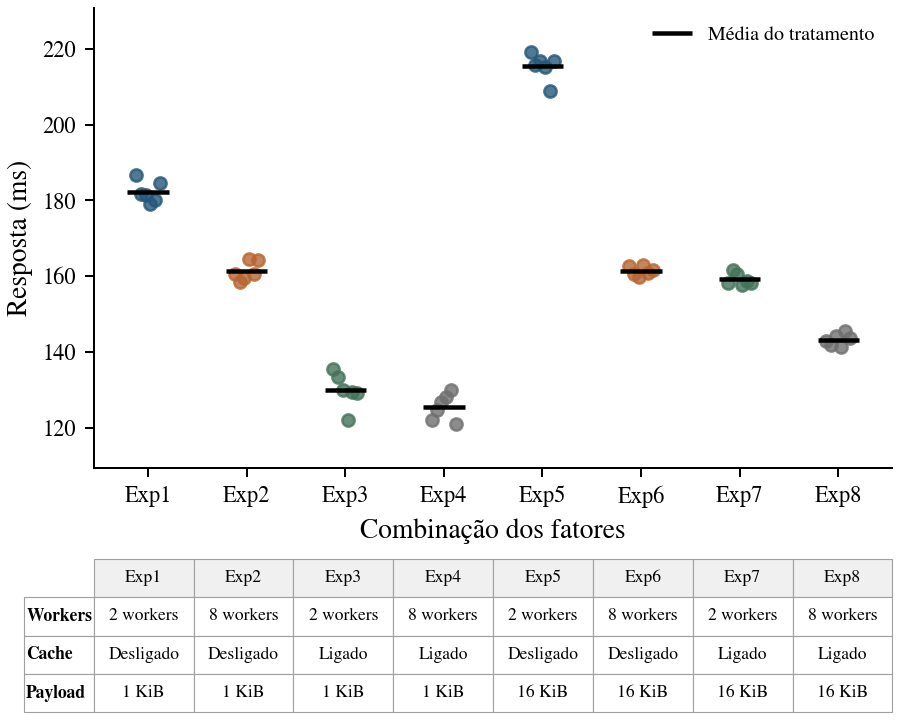

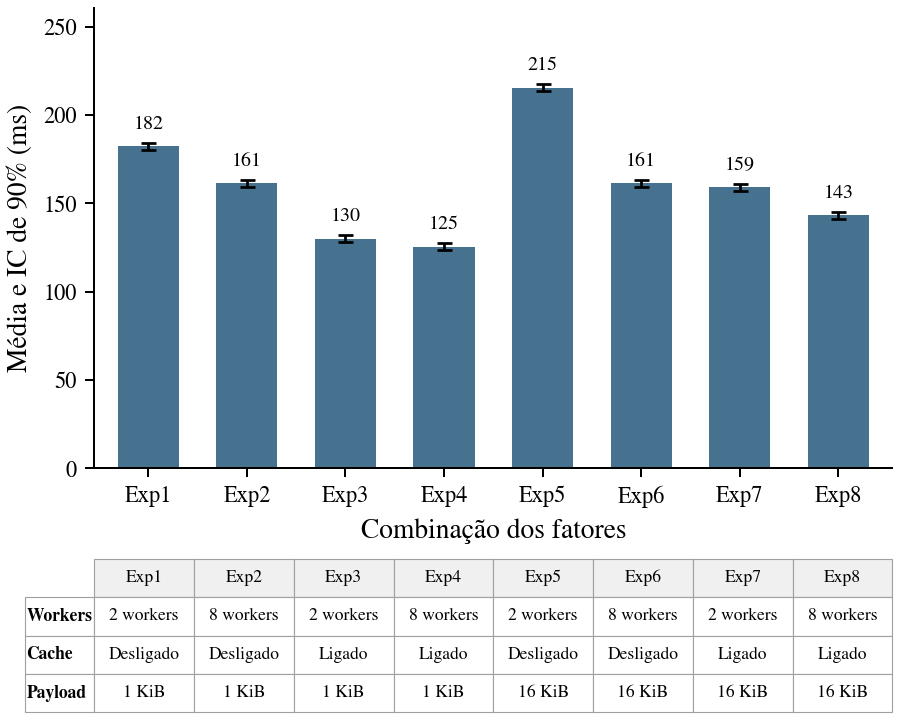

In [5]:
tabela_combinacoes = graficos_combinacoes(res, nomes, niveis_reais, "combinacoes")


## 4 Variação explicada e erro experimental

O erro puro vem das diferenças entre as sessões de uma mesma combinação. As somas de quadrados satisfazem

$$SST=\sum_{S\ne\varnothing}N\widehat q_S^2+SSE,\qquad
SSE=\sum_{i,j}(y_{ij}-\bar y_i)^2,\qquad
s_e^2=\frac{SSE}{2^k(r-1)}.$$

Cada porcentagem usa SST como denominador e inclui a parcela do erro. A alocação não informa o sinal de uma mudança nem a porcentagem de redução da resposta. As interações recebem parcelas próprias.


,Fonte,SS,Variação alocada (%)
0,A,6816.4,18.883
1,B,19887,55.091
2,AB,2229.6,6.1766
3,C,4852.8,13.444
4,AC,1481.9,4.1054
5,BC,143.52,0.3976
6,ABC,351.55,0.97389
7,Erro,335.15,0.92845


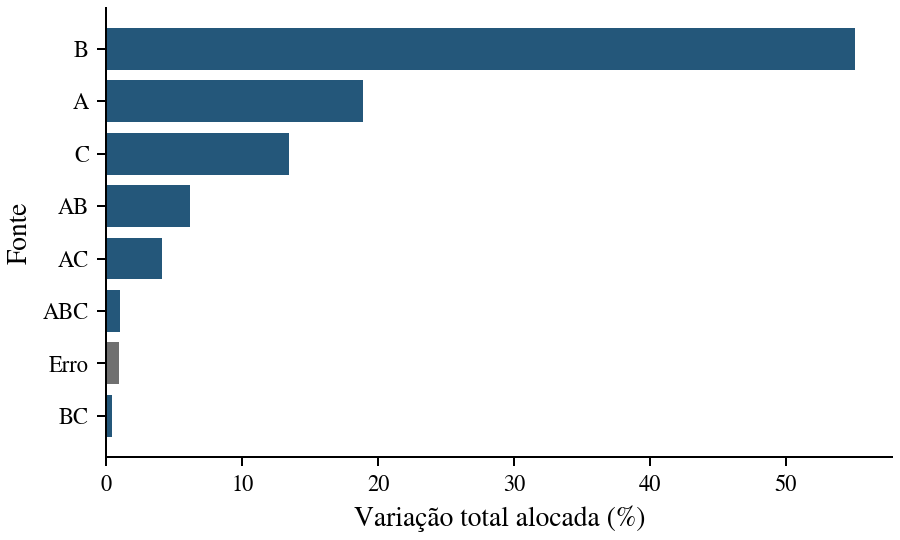

In [6]:
grafico_variacao(res, '04')


## 5 Intervalos e significância

Para cada termo não constante, $H_0$ afirma $q_S=0$ e $H_A$ afirma $q_S\ne0$. A estatística é $t=\widehat q_S/(s_e/\sqrt N)$ com $\nu=2^k(r-1)$. O valor-p bilateral é a probabilidade, sob a hipótese nula e as condições do modelo, de observar uma estatística tão extrema quanto a obtida.

O valor-p não é a probabilidade de a hipótese nula ser verdadeira. A significância não informa sozinha se a magnitude é relevante para a operação.


### Distribuições t e z nos intervalos

As convenções da aula usam $z_{1-\alpha/2}$ para um quantil da normal padrão e $t_{1-\alpha/2,\nu}$ para um quantil de Student. Para uma média de observações normais independentes, usamos z quando o desvio-padrão populacional $\sigma$ é conhecido. Quando $\sigma$ é estimado pela própria amostra, usamos t com os graus de liberdade da estimativa da variância.

No fatorial completo balanceado, $N=2^kr$ e $\nu=2^k(r-1)$. Como $\sigma$ é desconhecido, estimamos $s_e^2=SSE/\nu$ e construímos o IC individual de um coeficiente por

$$\widehat q_S\pm t_{1-\alpha/2,\nu}\frac{s_e}{\sqrt N}.$$

Se $\sigma$ fosse conhecido, substituiríamos $s_e$ por $\sigma$ e o quantil t por z. Para muitos graus de liberdade, t se aproxima de z. Ter mais de 30 observações não torna $\sigma$ conhecido nem exige abandonar t. A interpretação exata dos ICs clássicos pressupõe erros normais independentes com variância comum. Jain fornece a notação q e Montgomery apresenta essa relação com o modelo de regressão.

Os exemplos usam confiança de 90% e $\alpha=0{,}10$. O efeito alto menos baixo do contraste é $2q_S$. Seus dois limites também são multiplicados por dois. Os intervalos apresentados são individuais.


,Termo,q,EP de q,IC inferior,IC superior,Efeito 2q,t,Valor-p,Significativo
0,A,-11.917,0.4178,-12.62,-11.213,-23.834,-28.523,3.348e-28,Sim
1,B,-20.354,0.4178,-21.058,-19.651,-40.709,-48.718,3.09e-37,Sim
2,AB,6.8154,0.4178,6.1119,7.519,13.631,16.313,2.824e-19,Sim
3,C,10.055,0.4178,9.3514,10.758,20.11,24.066,2.074e-25,Sim
4,AC,-5.5564,0.4178,-6.2599,-4.8529,-11.113,-13.299,2.866e-16,Sim
5,BC,1.7292,0.4178,1.0257,2.4327,3.4584,4.1388,0.0001746,Sim
6,ABC,2.7063,0.4178,2.0028,3.4098,5.4126,6.4775,1.008e-07,Sim


**Efeito qA**

É significativo porque o valor-p 3.348e-28 é menor ou igual a 0.10. Há evidência de que qA difere de zero nas condições do modelo.

**Efeito qB**

É significativo porque o valor-p 3.09e-37 é menor ou igual a 0.10. Há evidência de que qB difere de zero nas condições do modelo.

**Efeito qAB**

É significativo porque o valor-p 2.824e-19 é menor ou igual a 0.10. Há evidência de que qAB difere de zero nas condições do modelo.

**Efeito qC**

É significativo porque o valor-p 2.074e-25 é menor ou igual a 0.10. Há evidência de que qC difere de zero nas condições do modelo.

**Efeito qAC**

É significativo porque o valor-p 2.866e-16 é menor ou igual a 0.10. Há evidência de que qAC difere de zero nas condições do modelo.

**Efeito qBC**

É significativo porque o valor-p 0.0001746 é menor ou igual a 0.10. Há evidência de que qBC difere de zero nas condições do modelo.

**Efeito qABC**

É significativo porque o valor-p 1.008e-07 é menor ou igual a 0.10. Há evidência de que qABC difere de zero nas condições do modelo.

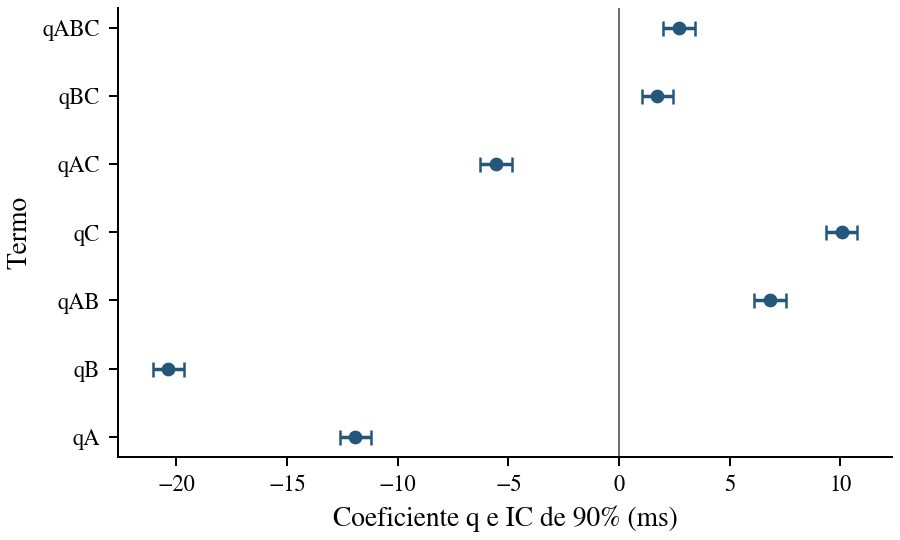

In [7]:
mostrar_resultados(res)
graficos_efeitos(res, '05')


## 6 Teste F do modelo

O teste global usa $H_0$ de todos os coeficientes não constantes iguais a zero. Em $H_A$, pelo menos um difere. Sua estatística é

$$F=\frac{\left(\sum_{S\ne\varnothing}SS_S\right)/(2^k-1)}{MSE}.$$

O numerador tem $2^k-1$ graus de liberdade e o denominador tem $2^k(r-1)$. Para um termo isolado, $F_S=t_S^2$. Um F global significativo indica diferenças entre as médias das combinações e não demonstra que as condições do modelo sejam verdadeiras.


### Como ler a ANOVA

A ANOVA organiza a mesma decomposição usada na alocação da variação.

| Coluna | Leitura |
| --- | --- |
| SS ou SQ | Soma de quadrados atribuída ao termo ou ao erro, na unidade da resposta ao quadrado |
| gl | Graus de liberdade usados naquela parcela |
| MS ou QM | Quadrado médio, calculado por SQ dividida por gl |
| F | Razão entre o quadrado médio do termo e o quadrado médio do erro |
| Valor-p | Probabilidade de um F pelo menos tão grande sob a hipótese nula e as condições do modelo |

No fatorial completo balanceado, cada termo possui um grau de liberdade. O erro possui $\nu=2^k(r-1)$ e seu quadrado médio é $MSE=SSE/\nu$. O total possui $N-1$ graus de liberdade. Assim,

$$F_S=\frac{QM_S}{MSE}=\frac{SS_S/1}{SSE/\nu}.$$

As referências são $F_{1,\nu}$ por termo e $F_{2^k-1,\nu}$ para o modelo. A decisão usa as hipóteses já apresentadas. Um valor-p menor ou igual a $\alpha$ leva à rejeição da hipótese correspondente. Um valor maior indica evidência insuficiente para rejeitá-la.

A alocação mostra $100SS_S/SST$. A ANOVA compara cada parcela com a variação entre réplicas por meio do MSE. Por isso, uma parcela pequena de SST ainda pode ser significativa quando o erro é pequeno. O teste não informa sozinho a direção ou a importância prática do efeito. As linhas de erro e total não recebem testes F próprios.


In [8]:
mostrar_anova(res)


,Fonte,SS,gl,MS,F,Valor-p
0,A,6816.4,1,6816.4,813.55,3.348e-28
1,B,19887,1,19887,2373.5,3.09e-37
2,AB,2229.6,1,2229.6,266.11,2.824e-19
3,C,4852.8,1,4852.8,579.19,2.074e-25
4,AC,1481.9,1,1481.9,176.87,2.866e-16
5,BC,143.52,1,143.52,17.13,0.0001746
6,ABC,351.55,1,351.55,41.958,1.008e-07
7,Erro,335.15,40,8.3787,NaN,
8,Total,36098,47,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p
0,609.75,7,40,1.469e-38


**Teste F global**

É significativo porque o valor-p 1.469e-38 é menor ou igual a 0.10. Há evidência de que pelo menos um termo do modelo difere de zero.

## 7 Efeitos nos níveis e interações

As médias por nível fazem uma média sobre os demais fatores. A leitura marginal precisa ser complementada pelas interações. Nos gráficos seguintes, cada par de fatores aparece condicionado aos níveis dos fatores restantes. Assim, uma interação de ordem maior não fica escondida pela média entre condições.

As barras representam ICs individuais de 90% das médias. Sua sobreposição não substitui um teste da diferença entre médias.


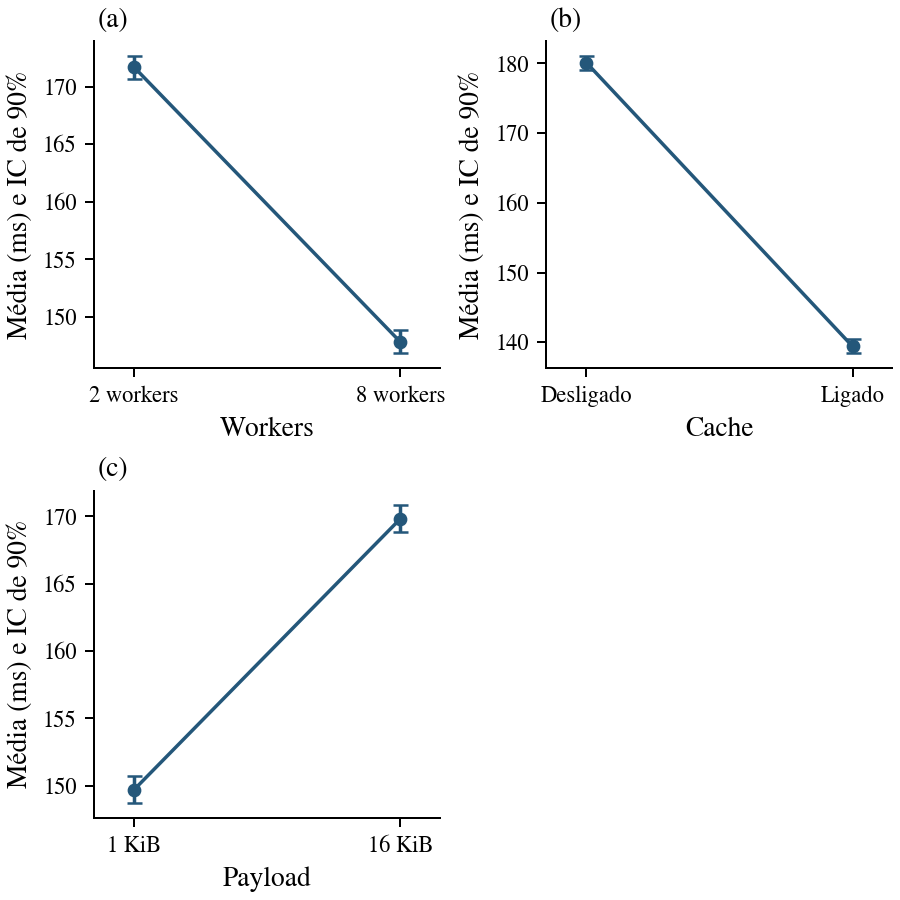

Painéis do gráfico. (a) Workers e Cache, Payload em 1 KiB. (b) Workers e Cache, Payload em 16 KiB. (c) Workers e Payload, Cache em Desligado. (d) Workers e Payload, Cache em Ligado. (e) Cache e Payload, Workers em 2 workers. (f) Cache e Payload, Workers em 8 workers.

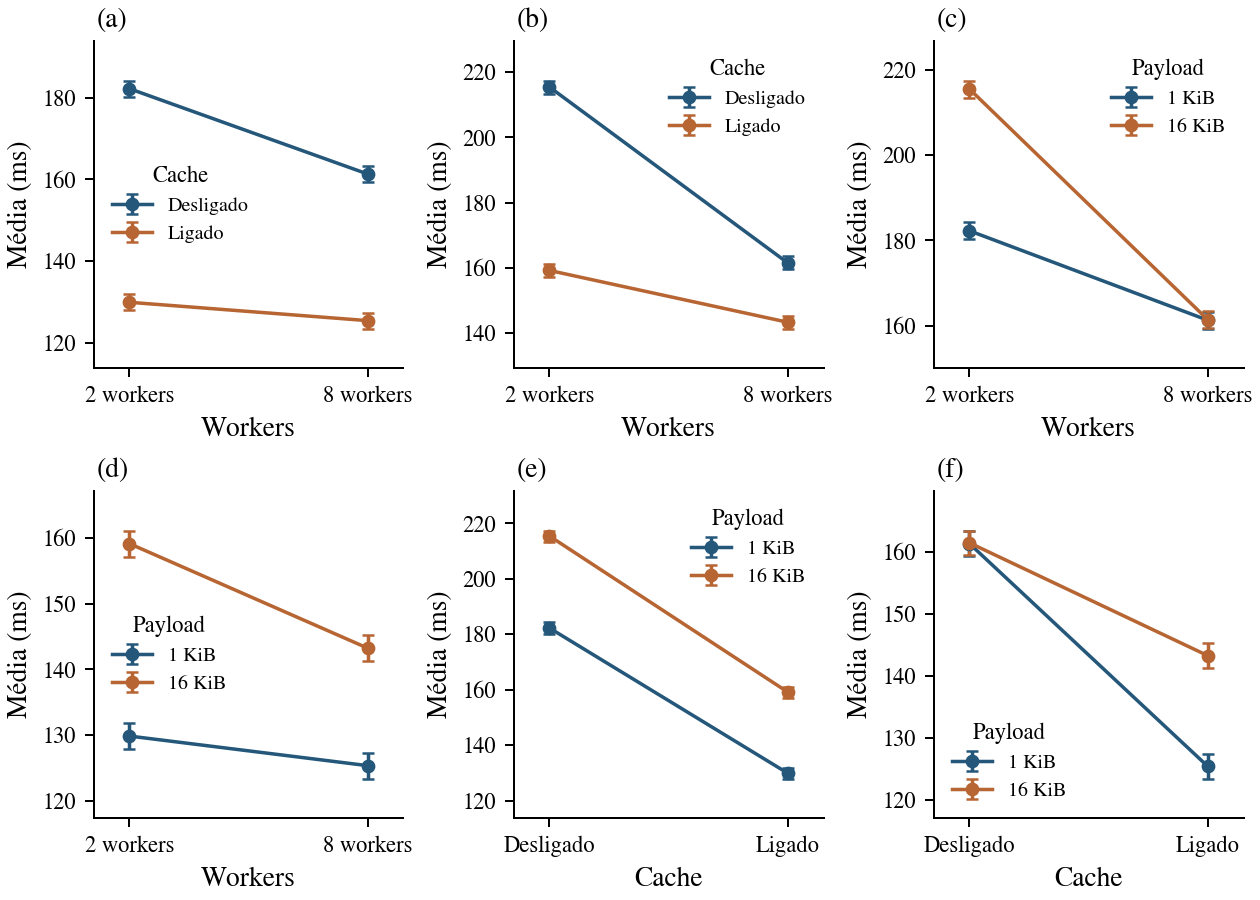

In [9]:
graficos_niveis(res, nomes, niveis_reais, '07')
graficos_interacoes(res, nomes, niveis_reais, '08')


## 8 Resíduos e condições do modelo

Os painéis mostram a relação com o ajuste, a dispersão dentro de cada combinação, o Q-Q e a sequência de execução. O objetivo é investigar a forma média, a variância, a normalidade e a independência dos erros.


### Condições do modelo

**Forma da resposta média**

O modelo precisa representar as médias nas condições estudadas. O completo reproduz as médias das combinações fatoriais. Isso deixa zero grau de liberdade para testar falta de ajuste entre esses pontos e não demonstra ausência de curvatura entre os níveis. O gráfico de resíduos contra os valores ajustados ajuda a investigar padrões, mas não certifica a forma do modelo.

**Homocedasticidade dos erros**

A variância deve permanecer aproximadamente constante. O teste de Levene centrado na mediana, conhecido como Brown e Forsythe, usa $H_0$ de variâncias iguais entre as combinações. Em $H_A$, pelo menos uma difere. Sua referência F é aproximada. O gráfico por combinação complementa o teste.

**Independência dos erros**

Os erros de sessões distintas não devem apresentar dependência sistemática. A ordem realmente executada é preservada no gráfico temporal. Durbin e Watson compara diferenças entre resíduos sucessivos com sua soma de quadrados. Valores próximos de 2 sugerem pouca associação de primeira ordem, valores menores sugerem associação positiva e maiores sugerem associação negativa. A referência usada para o valor-p simula erros normais independentes com variância comum sob o mesmo desenho. A alternativa procura dependência serial. O protocolo e o gráfico continuam necessários.

**Normalidade dos erros**

O Q-Q compara os quantis dos resíduos com os da normal. Nos testes de Shapiro e Wilk e de Kolmogorov e Smirnov, $H_0$ afirma normalidade dos erros e $H_A$ afirma desvio dessa forma. O segundo usa média e variância estimadas, como na formulação de Lilliefors. Como os resíduos compartilham parâmetros ajustados, os valores-p dos dois testes são calibrados com erros normais e o mesmo ajuste fatorial. Essa referência depende das demais condições do modelo. Durbin e Watson avalia dependência temporal, não normalidade.

Um teste significativo apresenta evidência contra sua hipótese nula. Um resultado não significativo indica evidência insuficiente para rejeitá-la. Nenhum valor-p demonstra que uma condição é verdadeira. A decisão considera os gráficos, a unidade experimental e o protocolo.


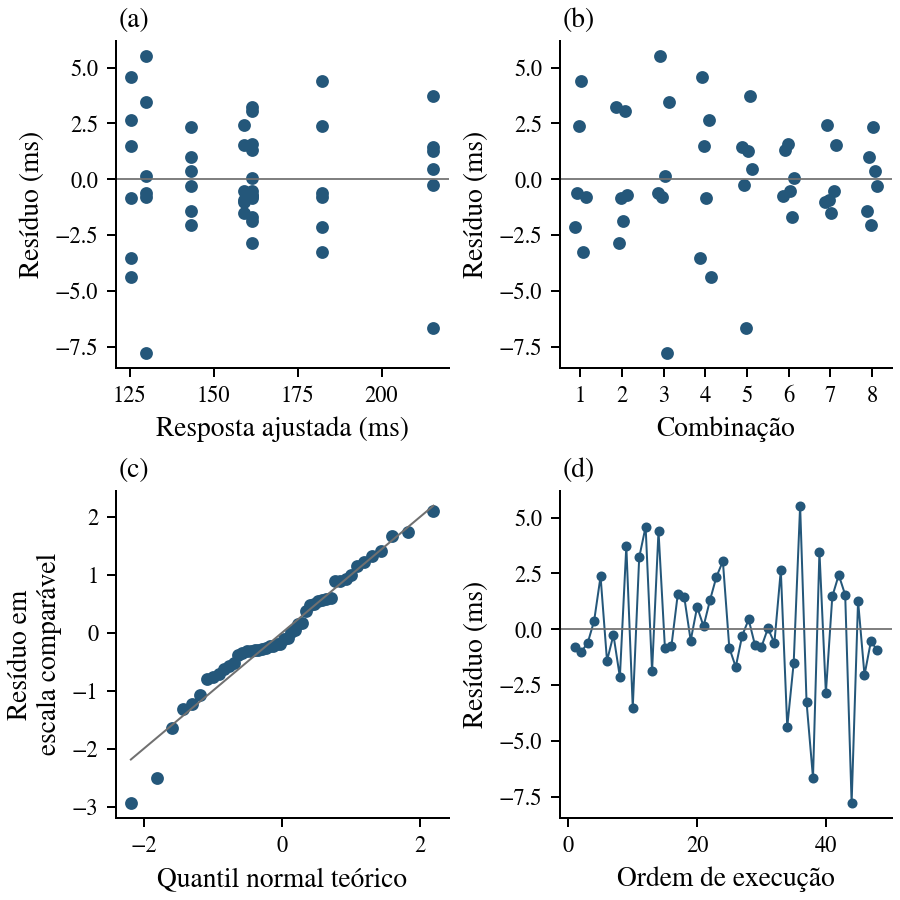

,Diagnóstico,Estatística,Valor-p,Referência
0,Brown e Forsythe,0.9871,0.4543,F aproximada
1,Shapiro e Wilk,0.96819,0.2098,Normal no mesmo desenho
2,Kolmogorov e Smirnov,0.10358,0.2214,Normal no mesmo desenho
3,Durbin e Watson,2.5447,0.0476,Normal independente no mesmo desenho


**Homocedasticidade**

Não é significativo porque o valor-p 0.4543 é maior que 0.10. Não há evidência suficiente contra a igualdade das variâncias.

**Shapiro e Wilk**

Não é significativo porque o valor-p 0.2098 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Kolmogorov e Smirnov**

Não é significativo porque o valor-p 0.2214 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Durbin e Watson**

É significativo porque o valor-p 0.0476 é menor ou igual a 0.10. Há evidência de dependência serial na comparação com a referência independente.

In [10]:
grid_residuos(res, ordem, '09')
tabela_diagnosticos = diagnosticos(res, ordem, '10')


## 9 Leitura do experimento

Os coeficientes mostram direção e magnitude dos contrastes. A alocação da variação indica quais contrastes respondem pelas maiores diferenças quadráticas observadas. Os intervalos e os valores-p expressam a incerteza sob as condições assumidas.

Um efeito principal resume os demais fatores. Com interações presentes, a mudança de uma configuração depende dos níveis mantidos fixos. A comparação entre os painéis condicionais permite avaliar essas mudanças. Os resultados valem para os níveis ensaiados e para o protocolo representado pelas sessões.

O custo da coleta é $2^kr$. A análise exige todas as combinações e replicações independentes. Para outro k, o cadastro dos fatores, os níveis reais e o gerador definem o novo conjunto artificial. As funções constroem automaticamente os termos, as tabelas, os testes e os gráficos condicionais. Blocos, dados ausentes e fatoriais fracionados exigem outro modelo.


## Referências

- Aula de Projeto e Análise de Experimentos. Material da disciplina.
- Raj Jain. *The Art of Computer Systems Performance Analysis*. Wiley, 1991. Capítulos 16 a 18. [Material do autor](https://www.cse.wustl.edu/~jain/books/perf_sli.htm) e [errata](https://www.cse.wustl.edu/~jain/books/ftp/errors_all.pdf).
- Douglas C. Montgomery. *Design and Analysis of Experiments*. Planejamento fatorial, análise de variância e adequação de modelos. [Sumário da editora](https://bcs.wiley.com/he-bcs/Books?action=contents&bcsId=11447&itemId=1119492440).
- NIST/SEMATECH. [Delineamentos fatoriais de dois níveis](https://www.itl.nist.gov/div898/handbook/pri/section3/pri3331.htm), [intervalos para a média](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm) e [Levene](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35a.htm).
- SciPy. [Shapiro e Wilk](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html). Statsmodels. [Lilliefors](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.lilliefors.html) e [Durbin e Watson](https://www.statsmodels.org/stable/generated/statsmodels.stats.stattools.durbin_watson.html). SciPy. [Calibração Monte Carlo com parâmetros estimados](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html). Referências de implementação dos diagnósticos.
